# 01 · The HAI water process (Siemens S7-300)
Our one dataset is **HAI** (HIL-based Augmented ICS), https://github.com/icsdataset/hai, CC BY-SA 4.0.
We use only its **water process (P3)**: a small loop that pumps water into an upper tank, run by a
**Siemens S7-300 PLC**. A hydro-turbine simulation (P4_HT) sets the demand the water process must follow.

- **HAI 22.04:** 279 h of normal operation, 4 test files, 58 attacks, **10 on the water process**.
- **HAI 23.05:** same testbed setup, 249 h of normal operation, 2 test files, 52 attacks, **1 on the water process**.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from src.data_loading import load_hai, FILES, attack_episodes, NAMES, ATTACK_TYPES
pd.DataFrame({"reading": list(NAMES), "meaning (HAI technical document)": list(NAMES.values())})

,reading,meaning (HAI technical document)
0,P3_LIT01,Upper tank water level (%)
1,P3_LH01,High water level setpoint (%)
2,P3_LL01,Low water level setpoint (%)
3,P3_LCV01D,Valve position command
4,P3_LCP01D,Pump speed command
5,P3_FIT01,Flow into the upper tank
6,P3_PIT01,Pressure into the upper tank
7,P4_HT_FD,Hydro turbine frequency deviation
8,P4_HT_PO,Hydro turbine output power (MW)
9,P4_HT_PS,Hydro turbine scheduled power (MW)


## Normal operation
Three hours from the first normal file. The controller drives the valve and pump to keep the tank level
between the low and high setpoints while following the hydro-turbine demand.

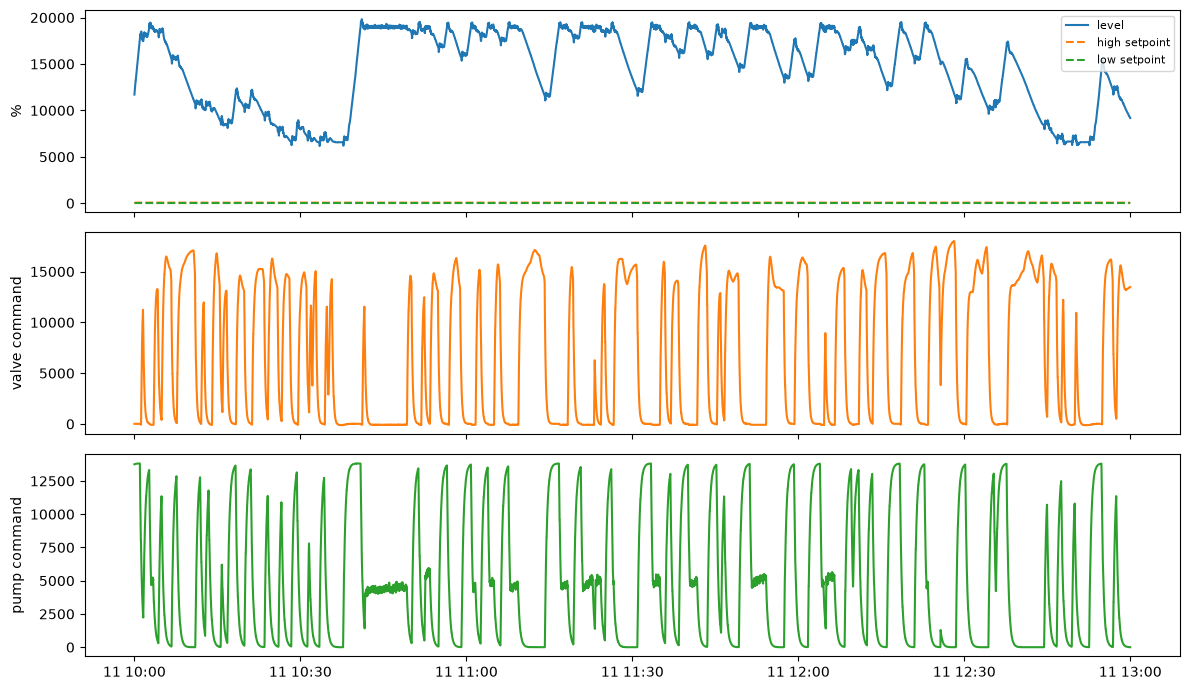

In [3]:
normal = load_hai("22.04", ["train1"])
w = normal.iloc[: 3 * 3600]
fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
ax[0].plot(w.timestamp, w.P3_LIT01, label="level"); ax[0].plot(w.timestamp, w.P3_LH01, "--", label="high setpoint"); ax[0].plot(w.timestamp, w.P3_LL01, "--", label="low setpoint")
ax[0].set_ylabel("%"); ax[0].legend(fontsize=8)
ax[1].plot(w.timestamp, w.P3_LCV01D, color="tab:orange"); ax[1].set_ylabel("valve command")
ax[2].plot(w.timestamp, w.P3_LCP01D, color="tab:green"); ax[2].set_ylabel("pump command")
plt.tight_layout()

## The attacks
HAI labels every second as attack or normal. We match each labeled attack to HAI's attack tables to find
the ones that hit the water process. Two table entries contradict themselves (a water scenario code with
boiler targets, or the reverse); they are kept out of every count and reported separately.

In [4]:
tests = {v: load_hai(v, FILES[(v, "test")]) for v in ["22.04", "23.05"]}
eps = pd.concat([attack_episodes(df) for df in tests.values()], ignore_index=True)
print(eps.groupby(["version", "target"]).size().unstack(fill_value=0))
water = eps[eps.target == "water"].copy()
water["what the attacker does"] = water.scenario.map(lambda s: " + ".join(ATTACK_TYPES[x] for x in s.split("+")))
water[["id", "version", "start", "seconds", "what the attacker does", "also_hits"]]

target   ambiguous  elsewhere  water
version                             
22.04            2         46     10
23.05            0         51      1


,id,version,start,seconds,what the attacker does,also_hits
3,A104,22.04,2021-07-10 15:39:12,55,"Valve command pushed up or down, then restored",NaN
11,A205,22.04,2021-07-13 21:10:07,56,"Valve command pushed up or down, then restored",NaN
18,A212,22.04,2021-07-14 08:11:12,56,Pump command replaced with an earlier value,NaN
20,A214,22.04,2021-07-14 11:23:17,614,Valve command changed for more than 10 minutes,NaN
26,A303,22.04,2021-07-14 23:22:01,144,"Valve command pushed up or down, then restored",boiler
27,A304,22.04,2021-07-15 01:41:07,92,Valve command changed while the level reading ...,NaN
33,A310,22.04,2021-07-15 09:52:12,2025,Pump command replaced with an earlier value + ...,NaN
37,A404,22.04,2021-07-15 15:08:01,98,"Valve command pushed up or down, then restored",turbine
47,A414,22.04,2021-07-16 07:20:12,78,Pump command changed while the level reading i...,turbine
52,A419,22.04,2021-07-16 14:59:07,164,Pump command replaced with an earlier value,boiler


### What an attack looks like
A214: the valve command is changed for more than 10 minutes. Shaded = attack.

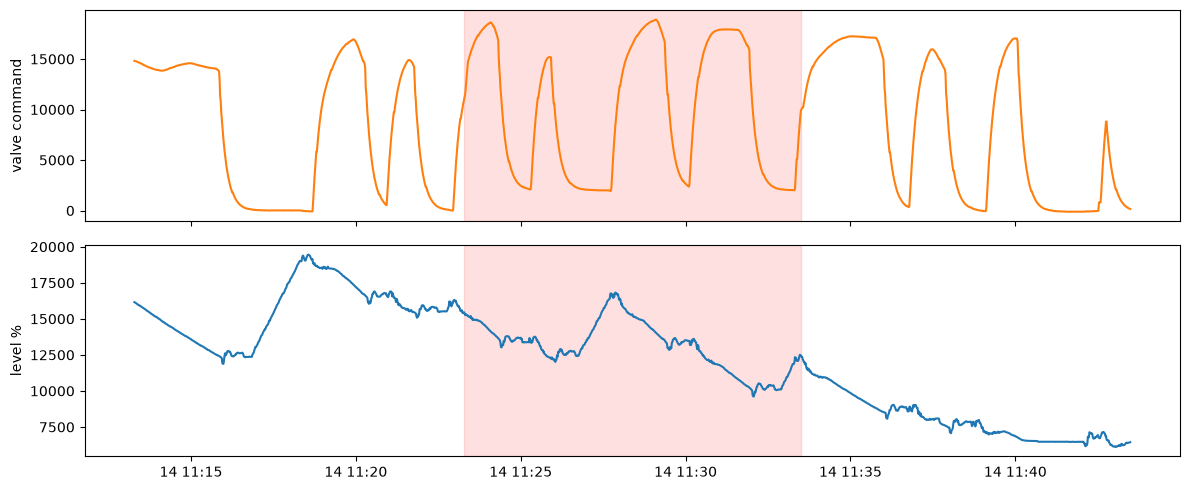

In [5]:
t = tests["22.04"]; e = water[water.id == "A214"].iloc[0]
w = t.iloc[max(0, e.i0 - 600): e.i1 + 600]
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
ax[0].plot(w.timestamp, w.P3_LCV01D, color="tab:orange"); ax[0].set_ylabel("valve command")
ax[1].plot(w.timestamp, w.P3_LIT01); ax[1].set_ylabel("level %")
for a in ax: a.axvspan(e.start, e.end, color="red", alpha=0.12)
plt.tight_layout()